# Étape 6 : Clustering des profils de risque

**Client :** NASA/JPL Planetary Defense Coordination Office (PDCO)

### Ce qu'on cherche

Les étapes 4 et 5 donnent un score **par objet**. Mais la PDCO organise son travail en **campagnes d'observation** : un même télescope, une même stratégie, pour un ensemble d'objets semblables. La question de cette étape :

> **Le catalogue se découpe-t-il naturellement en quelques profils de risque, chacun appelant une stratégie de suivi différente ?**

### Ce qu'on fait

| | |
|---|---|
| **Méthode** | K-Means (apprentissage **non supervisé** : aucune cible) |
| **Objets** | Tout le catalogue (41 281 objets, moins ceux sans MOID) |
| **Variables** | Taille (diamètre de l'étape 4), proximité (MOID), inclinaison, excentricité |
| **Choix de K** | Méthode du coude et score de silhouette |
| **Après coup** | On décrit chaque groupe avec des informations **non utilisées** pour le former : part de PHA, probabilité de l'étape 5, approches proches 2015–2035, famille orbitale |

### Ce qu'on veut éviter

À l'étape 2, on a vu que les familles Apollo, Amor, Aten et Atira sont **définies par des seuils sur l'orbite**. Un clustering qui les retrouverait n'apprendrait rien. On vérifiera donc que nos groupes **mélangent** ces familles.

Ce notebook utilise les sorties des étapes 4 et 5 : exécutez les notebooks 03, 04 et 05 avant celui-ci.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import ListedColormap
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score, silhouette_samples, silhouette_score
from sklearn.preprocessing import StandardScaler

pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

def find_project_dir() -> Path:
    for base in [Path.cwd(), *Path.cwd().parents]:
        for candidate in (base, base / "nasa-project"):
            if (candidate / "data" / "raw").is_dir():
                return candidate
    raise FileNotFoundError("Dossier nasa-project/data/raw introuvable.")

PROJECT_DIR = find_project_dir()
RAW_DIR = PROJECT_DIR / "data" / "raw"
DIAM_FILE = PROJECT_DIR / "data" / "processed" / "04_diameter" / "catalogue_diametres.csv"
SCORE_FILE = PROJECT_DIR / "data" / "processed" / "05_classification" / "scores_catalogue.csv"
PROCESSED_DIR = PROJECT_DIR / "data" / "processed" / "06_clustering"
REPORT_DIR = PROJECT_DIR / "reports" / "06_clustering"
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
REPORT_DIR.mkdir(parents=True, exist_ok=True)
for f, step in [(DIAM_FILE, "04_diameter_regression"), (SCORE_FILE, "05_classification")]:
    if not f.exists():
        raise FileNotFoundError(f"Exécutez d'abord {step}.ipynb.")

RANDOM_STATE = 42
LD_AU = 0.00257   # 1 distance lunaire en UA

# Palette catégorielle ordonnée (un cluster = une couleur, toujours la même)
CLUSTER_COLORS = ["#2878B5", "#E07A2D", "#3A8F5C", "#8E5BAA", "#C0392B", "#8C6D31"]
GREY, RED = "#8C8C8C", "#C0392B"
LABEL_BOX = dict(facecolor="white", edgecolor="none", alpha=0.85, pad=1.5)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.25})

def save(fig, name):
    fig.savefig(REPORT_DIR / f"{name}.png", dpi=160, bbox_inches="tight")

def fmt(n):
    return f"{n:,.0f}".replace(",", " ")

## 1. Assembler les données

In [2]:
asteroids = pd.read_csv(sorted(RAW_DIR.glob("near_earth_asteroids_2025*.csv"))[0], low_memory=False)
approaches = pd.read_csv(sorted(RAW_DIR.glob("asteroid_close_approaches_2015_2035*.csv"))[0], low_memory=False)
diameters = pd.read_csv(DIAM_FILE)
scores = pd.read_csv(SCORE_FILE)

# Approches proches 2015–2035, résumées par objet (servent seulement à DÉCRIRE les clusters)
close = (approaches.groupby("designation")
         .agg(nb_approches=("dist_lunar", "size"), distance_min_DL=("dist_lunar", "min"),
              vitesse_max_kms=("velocity_km_s", "max"))
         .reset_index().rename(columns={"designation": "pdes"}))

data = (asteroids[["pdes", "full_name", "pha", "class", "moid_au", "i", "e", "a", "q", "ad", "H"]]
        .merge(diameters[["pdes", "diametre_km", "diametre_km_haut", "source_diametre", "hors_domaine"]], on="pdes", how="left")
        .merge(scores[["pdes", "proba_pha", "signale"]], on="pdes", how="left")
        .merge(close, on="pdes", how="left"))
data["nb_approches"] = data["nb_approches"].fillna(0).astype(int)

missing = data["moid_au"].isna() | data["diametre_km"].isna()
print(f"Objets sans MOID ou sans diamètre, écartés du clustering : {missing.sum()} ({missing.mean():.1%})")
data = data[~missing].reset_index(drop=True)
print(f"Objets clusterisés : {fmt(len(data))}")

Objets sans MOID ou sans diamètre, écartés du clustering : 131 (0.3%)
Objets clusterisés : 41 150


## 2. Choix des variables

Quatre variables, chacune répondant à une question différente pour la PDCO :

| Variable | Question | Transformation |
|---|---|---|
| **Diamètre** (étape 4) | Quelle gravité en cas d'impact ? | log₁₀ : les tailles vont de 1 m à 30 km |
| **MOID** | L'orbite peut-elle passer près de la Terre ? | log₁₀ : la plupart des valeurs sont proches de 0 |
| **Inclinaison i** | L'objet reste-t-il près du plan de l'orbite terrestre ? Une forte inclinaison change les fenêtres d'observation et augmente la vitesse de rencontre. | aucune |
| **Excentricité e** | L'orbite est-elle allongée ? Une forte excentricité signifie des passages rapides et rares. | aucune |

`a`, `q` et `ad` sont écartées : elles sont redondantes avec e et le MOID (étape 2).

K-Means mesure des distances : toutes les variables sont **standardisées** pour avoir le même poids. Il n'y a ni cible ni généralisation à évaluer, donc pas de séparation train/test ici. `pha` ne sert **pas** au clustering, seulement à décrire les groupes ensuite.

In [3]:
features = pd.DataFrame({
    "log10_diametre": np.log10(data["diametre_km"]),
    "log10_moid": np.log10(data["moid_au"] + 1e-4),   # +1e-4 UA évite log(0)
    "inclinaison": data["i"],
    "excentricite": data["e"],
})
X = StandardScaler().fit_transform(features)
features.describe().T[["mean", "std", "min", "50%", "max"]]

,mean,std,min,50%,max
log10_diametre,-1.130,0.611,-3.292,-1.206,1.576
log10_moid,-1.491,0.730,-3.998,-1.373,-0.150
inclinaison,11.840,10.550,0.010,8.400,165.600
excentricite,0.434,0.177,0.003,0.448,0.996


## 2 bis. Justification des variables : corrélations et ACP

Le choix précédent repose sur des arguments métier et physiques. On le vérifie maintenant avec deux outils statistiques :

1. **La matrice de corrélation** des variables candidates : deux variables très corrélées apportent la même information et donneraient un poids double à cette information dans K-Means.
2. **L'analyse en composantes principales (ACP)** sur les 4 variables retenues : elle indique si l'on pourrait les résumer en moins de dimensions sans perte importante.

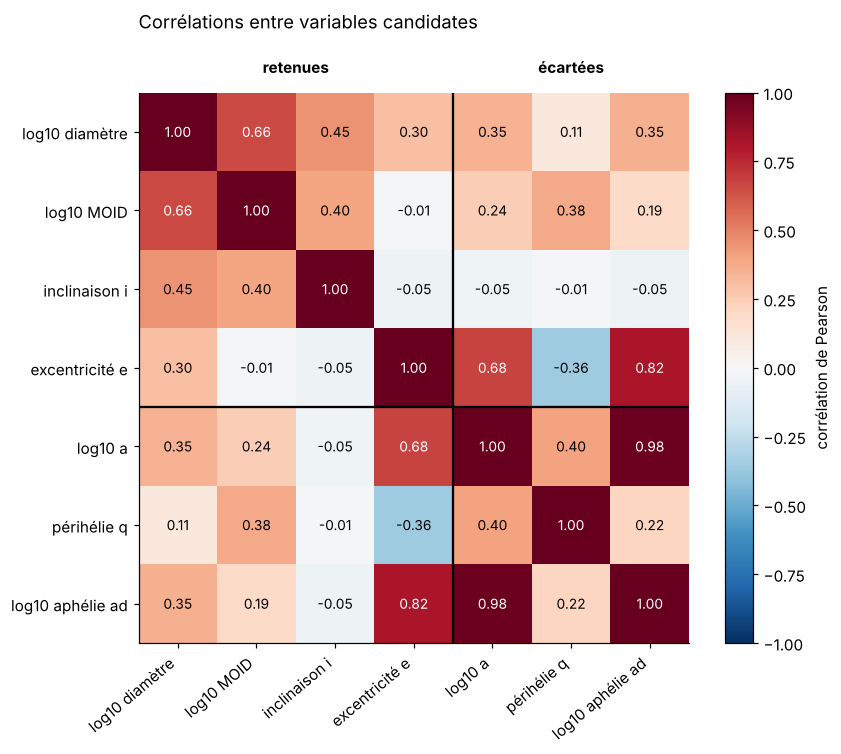

In [4]:
candidates = pd.DataFrame({
    "log10 diamètre": np.log10(data["diametre_km"]),
    "log10 MOID": np.log10(data["moid_au"] + 1e-4),
    "inclinaison i": data["i"],
    "excentricité e": data["e"],
    "log10 a": np.log10(data["a"]),
    "périhélie q": data["q"],
    "log10 aphélie ad": np.log10(data["ad"]),
})
corr = candidates.corr()
corr.round(2).to_csv(REPORT_DIR / "correlations_variables.csv")

fig, ax = plt.subplots(figsize=(8.5, 6.5))
im = ax.imshow(corr.values, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=40, ha="right")
ax.set_yticks(range(len(corr)), corr.index)
for r in range(len(corr)):
    for c in range(len(corr)):
        v = corr.values[r, c]
        ax.text(c, r, f"{v:.2f}", ha="center", va="center", fontsize=9,
                color="white" if abs(v) > 0.6 else "black")
ax.axhline(3.5, color="black", lw=1.5); ax.axvline(3.5, color="black", lw=1.5)
ax.text(1.5, -0.75, "retenues", ha="center", fontsize=10, fontweight="bold")
ax.text(5, -0.75, "écartées", ha="center", fontsize=10, fontweight="bold")
ax.grid(False)
fig.colorbar(im, ax=ax, fraction=0.04, label="corrélation de Pearson")
ax.set_title("Corrélations entre variables candidates", loc="left", pad=42)
save(fig, "correlations_variables")
plt.show()

**Lecture :**

- **`a` et `ad` sont presque identiques** (r ≈ 0,98) et `ad` suit fortement l'excentricité (r ≈ 0,8). Les garder avec `e` reviendrait à compter deux ou trois fois la même information.
- **`q`** est une combinaison de `a` et `e`, liée au MOID : elle n'apporte pas d'information indépendante. Elle sert aussi à définir les familles orbitales, qu'on ne veut pas redécouvrir.
- **Parmi les 4 variables retenues**, la seule corrélation forte est celle entre **taille et MOID** (r ≈ 0,66). Elle vient du **biais de détection** : un petit objet n'est découvert que s'il passe tout près de la Terre. On la garde, car taille et proximité sont deux dimensions distinctes du risque, mais il faut savoir qu'elle orientera les clusters.

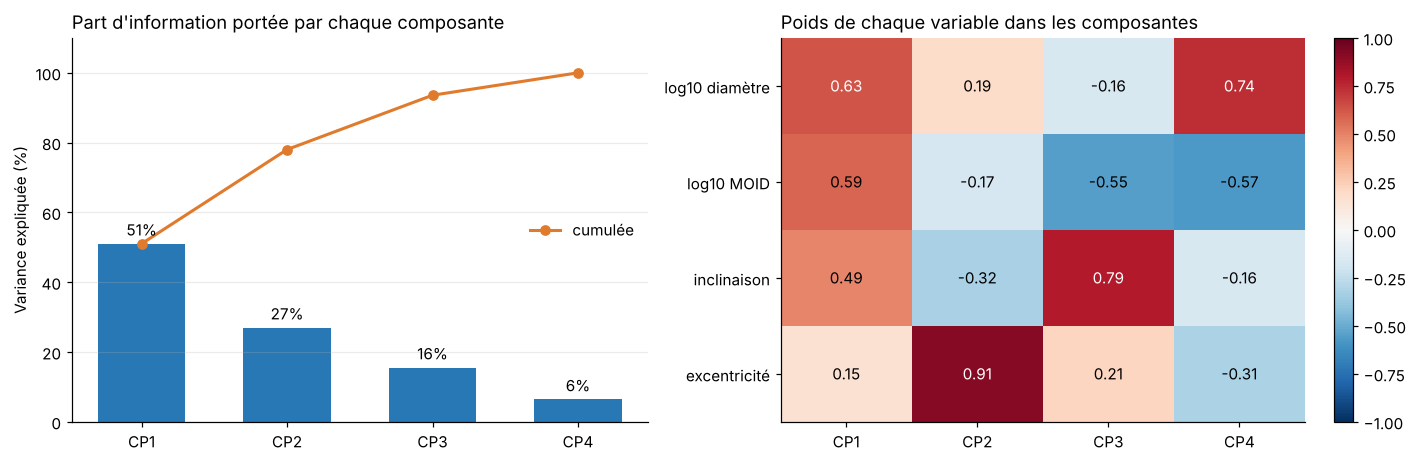

,variance expliquée,variance cumulée
CP1,0.510,0.510
CP2,0.270,0.780
CP3,0.156,0.936
CP4,0.064,1.000


In [5]:
pca = PCA().fit(X)
explained = pd.DataFrame({
    "variance expliquée": pca.explained_variance_ratio_,
    "variance cumulée": np.cumsum(pca.explained_variance_ratio_),
}, index=[f"CP{k + 1}" for k in range(X.shape[1])])
loadings = pd.DataFrame(pca.components_.T, index=features.columns,
                        columns=[f"CP{k + 1}" for k in range(X.shape[1])])
explained.to_csv(REPORT_DIR / "acp_variance.csv")
loadings.to_csv(REPORT_DIR / "acp_poids_variables.csv")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))
ax = axes[0]
bars = ax.bar(explained.index, explained["variance expliquée"] * 100, color=CLUSTER_COLORS[0], width=0.6)
ax.bar_label(bars, labels=[f"{v:.0%}" for v in explained["variance expliquée"]], padding=3)
ax.plot(explained.index, explained["variance cumulée"] * 100, marker="o", color=CLUSTER_COLORS[1], lw=2, label="cumulée")
ax.set_ylim(0, 110)
ax.set_ylabel("Variance expliquée (%)")
ax.set_title("Part d'information portée par chaque composante", loc="left")
ax.legend(frameon=False, loc="center right")
ax.grid(axis="x", visible=False)

ax = axes[1]
im = ax.imshow(loadings.values, cmap="RdBu_r", vmin=-1, vmax=1, aspect="auto")
ax.set_xticks(range(loadings.shape[1]), loadings.columns)
ax.set_yticks(range(len(loadings)), ["log10 diamètre", "log10 MOID", "inclinaison", "excentricité"])
for r in range(loadings.shape[0]):
    for c in range(loadings.shape[1]):
        v = loadings.values[r, c]
        ax.text(c, r, f"{v:.2f}", ha="center", va="center", fontsize=10, color="white" if abs(v) > 0.6 else "black")
ax.grid(False)
ax.set_title("Poids de chaque variable dans les composantes", loc="left")
fig.colorbar(im, ax=ax, fraction=0.04)
fig.tight_layout()
save(fig, "acp_variance_poids")
plt.show()
explained.round(3)

**Lecture :**

- **CP1 (environ la moitié de l'information)** combine taille, MOID et inclinaison : elle oppose les objets **petits, proches et peu inclinés** aux objets **gros, lointains et inclinés**. C'est l'axe du biais de détection.
- **CP2** est presque entièrement l'**excentricité**, qui varie indépendamment des autres.
- **CP3 et CP4** portent encore environ 20 % de l'information à elles deux.

**Décision :** il faut 3 composantes pour conserver plus de 90 % de l'information. Remplacer les 4 variables par 2 composantes ferait perdre plus de 20 % de l'information, et les clusters deviendraient plus difficiles à décrire pour la PDCO (« CP1 élevé » parle moins que « gros objets »). **On clusterise donc sur les 4 variables d'origine**, et l'ACP sert à visualiser le résultat (section 5).

## 3. Choisir le nombre de groupes K

- **Méthode du coude** : l'inertie (dispersion à l'intérieur des groupes) baisse toujours quand K augmente. On cherche le point où la baisse ralentit.
- **Score de silhouette** : pour chaque objet, compare la distance à son propre groupe et au groupe voisin. Il va de −1 à 1 : proche de 1, les groupes sont bien séparés ; proche de 0, ils se chevauchent.

La silhouette est calculée sur un échantillon de 10 000 objets pour rester rapide.

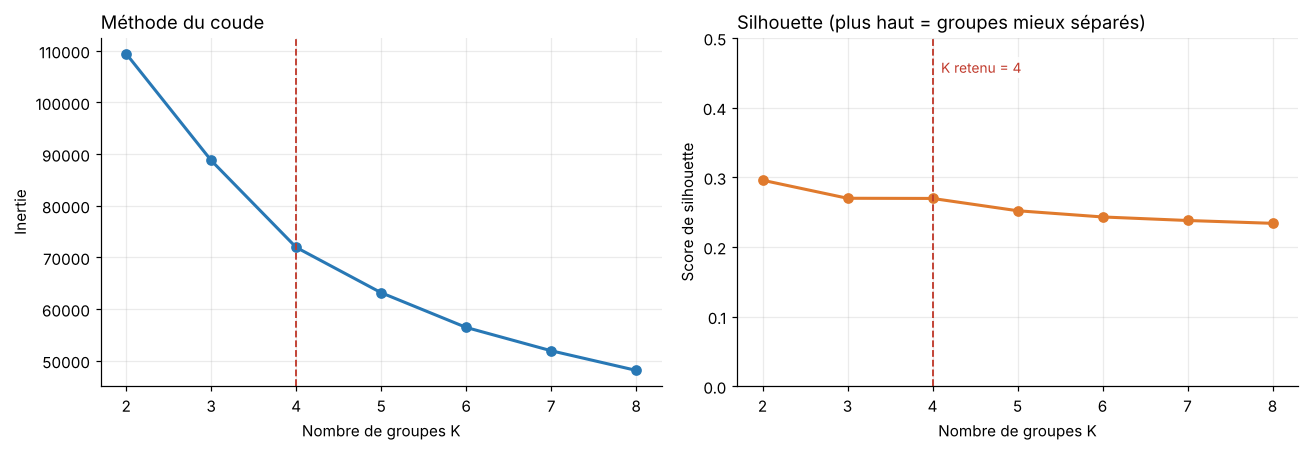

,K,inertie,silhouette
0,2,"109,435.870",0.296
1,3,"88,771.128",0.270
2,4,"71,941.877",0.270
3,5,"63,160.136",0.252
4,6,"56,442.423",0.243
5,7,"51,927.020",0.238
6,8,"48,125.509",0.234


In [6]:
rng = np.random.default_rng(RANDOM_STATE)
sample = rng.choice(len(X), size=min(10_000, len(X)), replace=False)

ks = range(2, 9)
inertia, silhouette = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X)
    inertia.append(km.inertia_)
    silhouette.append(silhouette_score(X[sample], km.labels_[sample]))

k_table = pd.DataFrame({"K": list(ks), "inertie": inertia, "silhouette": silhouette})
k_table.to_csv(REPORT_DIR / "choix_k.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
axes[0].plot(list(ks), inertia, marker="o", color=CLUSTER_COLORS[0], lw=2)
axes[0].set_xlabel("Nombre de groupes K"); axes[0].set_ylabel("Inertie")
axes[0].set_title("Méthode du coude", loc="left")
axes[1].plot(list(ks), silhouette, marker="o", color=CLUSTER_COLORS[1], lw=2)
axes[1].set_xlabel("Nombre de groupes K"); axes[1].set_ylabel("Score de silhouette")
axes[1].set_ylim(0, 0.5)
axes[1].set_title("Silhouette (plus haut = groupes mieux séparés)", loc="left")
K = 4
for ax in axes:
    ax.axvline(K, color=RED, ls="--", lw=1.2)
axes[1].text(K + 0.1, 0.45, f"K retenu = {K}", color=RED, fontsize=9, bbox=LABEL_BOX)
fig.tight_layout()
save(fig, "choix_k")
plt.show()
k_table.round(3)

**Lecture :**

- La silhouette est la plus haute pour K = 2, mais deux groupes (« petits » contre « gros ») ne suffisent pas à définir des campagnes différentes.
- Entre K = 3 et K = 4, la silhouette reste stable, puis elle baisse régulièrement. Le coude n'est pas net.
- **On retient K = 4** : c'est le plus grand nombre de groupes avant que la séparation ne se dégrade.

**Limite à annoncer :** une silhouette d'environ 0,27 indique des groupes **qui se chevauchent**. Les géocroiseurs forment un continuum, pas des familles bien distinctes. Les clusters sont donc des **découpages utiles pour organiser le travail**, pas des catégories naturelles.

## 4. Stabilité des groupes

In [7]:
reference = KMeans(n_clusters=K, n_init=10, random_state=RANDOM_STATE).fit(X)
labels_ref = reference.labels_
ari = [adjusted_rand_score(labels_ref, KMeans(n_clusters=K, n_init=10, random_state=s).fit_predict(X))
       for s in range(1, 6)]
print(f"Accord entre 5 relances avec des initialisations différentes (ARI) : "
      f"moyenne {np.mean(ari):.3f}, minimum {np.min(ari):.3f}  (1 = groupes identiques)")

Accord entre 5 relances avec des initialisations différentes (ARI) : moyenne 0.988, minimum 0.965  (1 = groupes identiques)


Un ARI proche de 1 signifie que K-Means retrouve **les mêmes groupes** quelle que soit son initialisation aléatoire. Les groupes se chevauchent, mais ils sont **reproductibles**.

## 5. Portrait de chaque groupe

In [8]:
# Renumérotation par diamètre médian croissant, pour des numéros stables et lisibles
order = pd.Series(np.log10(data["diametre_km"])).groupby(labels_ref).median().sort_values().index
relabel = {old: new for new, old in enumerate(order)}
data["cluster"] = pd.Series(labels_ref).map(relabel).to_numpy()

total_pha = data["pha"].sum()
profile = data.groupby("cluster").agg(
    objets=("pdes", "size"),
    diametre_median_m=("diametre_km", lambda s: s.median() * 1000),
    moid_median_UA=("moid_au", "median"),
    inclinaison_mediane=("i", "median"),
    excentricite_mediane=("e", "median"),
    part_PHA=("pha", "mean"),
    nb_PHA=("pha", "sum"),
    proba_pha_moyenne=("proba_pha", "mean"),
    part_signales_etape5=("signale", "mean"),
    part_approche_moins_5DL=("distance_min_DL", lambda s: (s < 5).sum() / len(s)),
    part_diametre_hors_domaine=("hors_domaine", "mean"),
)
profile["part_de_tous_les_PHA"] = profile["nb_PHA"] / total_pha
profile.to_csv(REPORT_DIR / "profils_clusters.csv")
profile.round(3).T

cluster,0,1,2,3
objets,"11,002.000","10,845.000","13,288.000","6,015.000"
diametre_median_m,18.582,41.898,162.880,383.364
moid_median_UA,0.005,0.046,0.078,0.170
inclinaison_mediane,4.030,11.290,7.485,28.470
excentricite_mediane,0.476,0.245,0.541,0.461
part_PHA,0.010,0.022,0.122,0.094
nb_PHA,107.000,241.000,"1,625.000",566.000
proba_pha_moyenne,0.056,0.075,0.266,0.314
part_signales_etape5,0.168,0.181,0.457,0.577
part_approche_moins_5DL,0.436,0.036,0.003,0.004


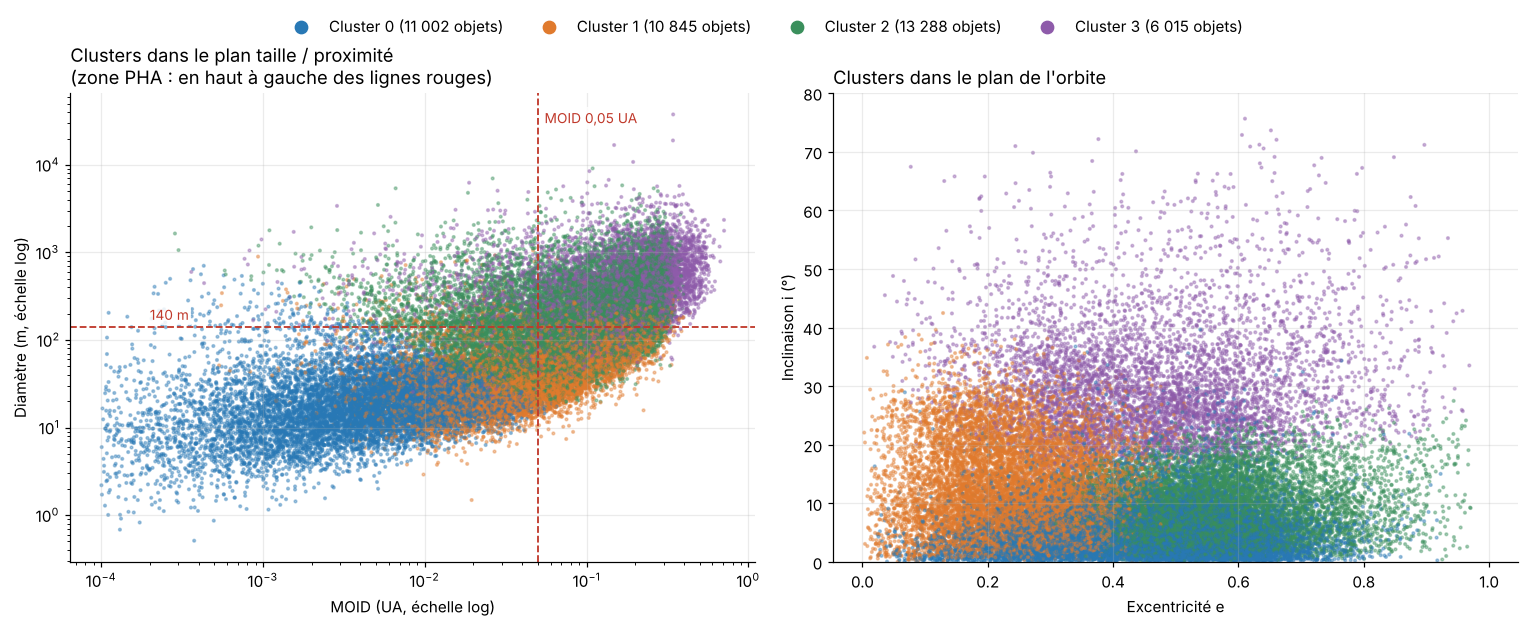

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
colors = ListedColormap(CLUSTER_COLORS[:K])

ax = axes[0]
ax.scatter(data["moid_au"] + 1e-4, data["diametre_km"] * 1000, c=data["cluster"], cmap=colors,
           s=3, alpha=0.4, rasterized=True, vmin=-0.5, vmax=K - 0.5)
ax.set_xscale("log"); ax.set_yscale("log")
ax.axvline(0.05, color=RED, ls="--", lw=1.2)
ax.axhline(140, color=RED, ls="--", lw=1.2)
ax.text(0.055, 3e4, "MOID 0,05 UA", color=RED, fontsize=9, bbox=LABEL_BOX)
ax.text(2e-4, 170, "140 m", color=RED, fontsize=9, bbox=LABEL_BOX)
ax.set_xlabel("MOID (UA, échelle log)")
ax.set_ylabel("Diamètre (m, échelle log)")
ax.set_title("Clusters dans le plan taille / proximité\n(zone PHA : en haut à gauche des lignes rouges)", loc="left")

ax = axes[1]
ax.scatter(data["e"], data["i"], c=data["cluster"], cmap=colors, s=3, alpha=0.4,
           rasterized=True, vmin=-0.5, vmax=K - 0.5)
ax.set_xlabel("Excentricité e")
ax.set_ylabel("Inclinaison i (°)")
ax.set_ylim(0, 80)
ax.set_title("Clusters dans le plan de l'orbite", loc="left")

handles = [plt.Line2D([], [], marker="o", ls="", color=CLUSTER_COLORS[c], markersize=8,
                      label=f"Cluster {c} ({fmt(profile.loc[c, 'objets'])} objets)") for c in range(K)]
fig.legend(handles=handles, loc="upper center", ncol=K, frameon=False, bbox_to_anchor=(0.5, 1.04))
fig.tight_layout()
save(fig, "clusters_projections")
plt.show()

### Vue d'ensemble : les clusters dans le plan de l'ACP

On projette tous les objets sur les deux premières composantes (environ 78 % de l'information), chaque point coloré par son cluster. Les flèches montrent la direction de chaque variable d'origine dans ce plan.

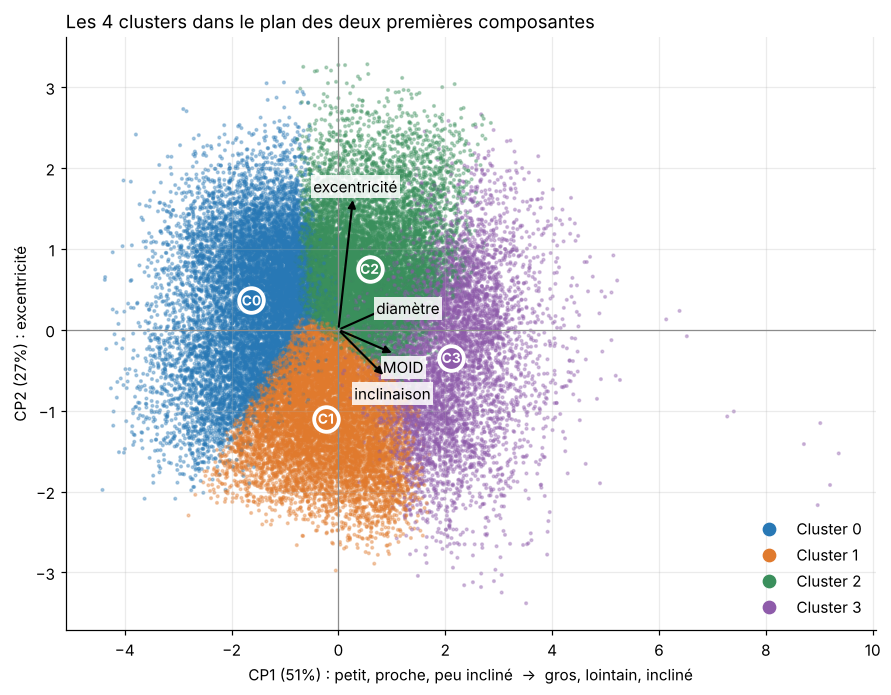

In [10]:
coords = pca.transform(X)[:, :2]
fig, ax = plt.subplots(figsize=(9.5, 7))
ax.scatter(coords[:, 0], coords[:, 1], c=data["cluster"], cmap=ListedColormap(CLUSTER_COLORS[:K]),
           s=3, alpha=0.35, rasterized=True, vmin=-0.5, vmax=K - 0.5)
centers = pd.DataFrame(coords).groupby(data["cluster"].to_numpy()).mean()
for c, (x0, y0) in centers.iterrows():
    ax.scatter(x0, y0, s=260, color=CLUSTER_COLORS[c], edgecolor="white", linewidth=2.5, zorder=5)
    ax.text(x0, y0, f"C{c}", ha="center", va="center", color="white", fontsize=9, fontweight="bold", zorder=6)
scale = 1.8
names = ["diamètre", "MOID", "inclinaison", "excentricité"]
for name, (lx, ly) in zip(names, pca.components_[:2].T):
    ax.annotate("", xy=(lx * scale, ly * scale), xytext=(0, 0),
                arrowprops=dict(arrowstyle="-|>", color="black", lw=1.4))
    ax.text(lx * scale * 1.15, ly * scale * 1.15 - 0.12, name, fontsize=10, ha="center", va="center", bbox=LABEL_BOX)
ax.axhline(0, color=GREY, lw=0.8); ax.axvline(0, color=GREY, lw=0.8)
ev = pca.explained_variance_ratio_
ax.set_xlabel(f"CP1 ({ev[0]:.0%}) : petit, proche, peu incliné  →  gros, lointain, incliné")
ax.set_ylabel(f"CP2 ({ev[1]:.0%}) : excentricité")
ax.set_title("Les 4 clusters dans le plan des deux premières composantes", loc="left")
handles = [plt.Line2D([], [], marker="o", ls="", color=CLUSTER_COLORS[c], markersize=8, label=f"Cluster {c}") for c in range(K)]
ax.legend(handles=handles, frameon=False, loc="lower right")
save(fig, "acp_projection_clusters")
plt.show()

**Lecture :** les clusters s'ordonnent le long de **CP1**, du cluster 0 (petits frôleurs, à gauche) au cluster 3 (gros objets inclinés, à droite). **CP2** sépare ensuite les orbites peu allongées (cluster 1, en bas) des orbites très allongées (clusters 0 et 2, en haut). Les nuages se touchent, ce qui confirme visuellement la silhouette modérée : ce sont des **régions d'un continuum**, pas des groupes isolés.

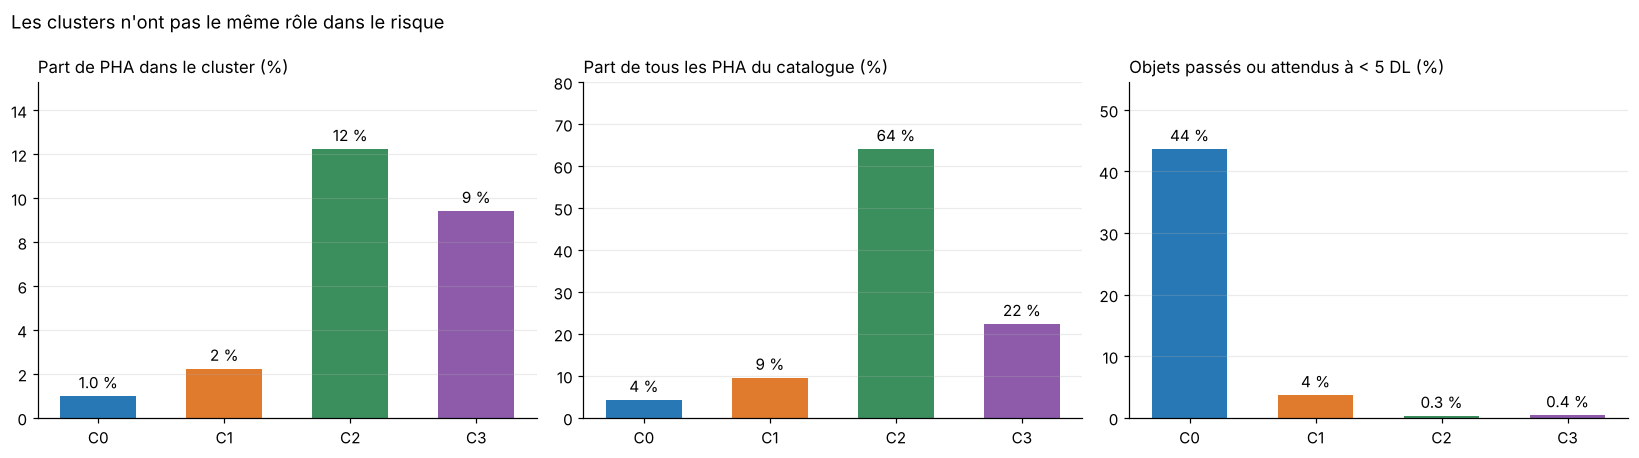

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
metrics = [
    ("part_PHA", "Part de PHA dans le cluster (%)", 100),
    ("part_de_tous_les_PHA", "Part de tous les PHA du catalogue (%)", 100),
    ("part_approche_moins_5DL", "Objets passés ou attendus à < 5 DL (%)", 100),
]
for ax, (col, title, scale) in zip(axes, metrics):
    vals = profile[col] * scale
    bars = ax.bar([f"C{c}" for c in profile.index], vals, color=CLUSTER_COLORS[:K], width=0.6)
    ax.bar_label(bars, labels=[f"{v:.0f} %" if v >= 1 else f"{v:.1f} %" for v in vals], padding=3)
    ax.set_ylim(0, vals.max() * 1.25)
    ax.set_title(title, loc="left", fontsize=11)
    ax.grid(axis="x", visible=False)
fig.suptitle("Les clusters n'ont pas le même rôle dans le risque", x=0.01, ha="left")
fig.tight_layout()
save(fig, "clusters_risque")
plt.show()

## 6. Les clusters retrouvent-ils les familles orbitales ?

Si chaque cluster correspondait à une famille (Apollo, Amor, Aten, Atira), le clustering n'apporterait rien de nouveau.

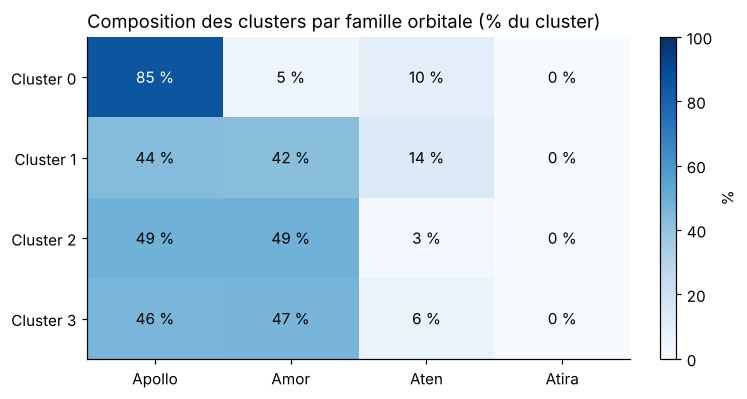

Accord clusters / familles (ARI) : 0.077  (0 = aucun lien)


In [12]:
family_names = {"APO": "Apollo", "AMO": "Amor", "ATE": "Aten", "IEO": "Atira"}
cross = pd.crosstab(data["cluster"], data["class"].map(family_names), normalize="index") * 100
cross = cross[[c for c in ["Apollo", "Amor", "Aten", "Atira"] if c in cross.columns]]
cross.to_csv(REPORT_DIR / "clusters_vs_familles.csv")

fig, ax = plt.subplots(figsize=(7, 3.8))
im = ax.imshow(cross.values, cmap="Blues", vmin=0, vmax=100, aspect="auto")
ax.set_xticks(range(cross.shape[1]), cross.columns)
ax.set_yticks(range(K), [f"Cluster {c}" for c in cross.index])
for r in range(cross.shape[0]):
    for c in range(cross.shape[1]):
        v = cross.values[r, c]
        ax.text(c, r, f"{v:.0f} %", ha="center", va="center", color="white" if v > 60 else "black", fontsize=10)
ax.grid(False)
ax.set_title("Composition des clusters par famille orbitale (% du cluster)", loc="left")
fig.colorbar(im, ax=ax, fraction=0.04, label="%")
save(fig, "clusters_vs_familles")
plt.show()
print(f"Accord clusters / familles (ARI) : {adjusted_rand_score(data['class'], data['cluster']):.3f}  (0 = aucun lien)")

**Lecture :**

- **Trois clusters sur quatre mélangent Apollo et Amor à parts presque égales**, et l'ARI entre clusters et familles est proche de 0. Le clustering ne redécouvre pas la classification officielle : il découpe le catalogue selon **d'autres critères**, liés au risque (taille, proximité, inclinaison) plutôt qu'à la seule géométrie de l'orbite.
- **Le cluster 0 est à 85 % Apollo.** C'est cohérent : ses objets frôlent l'orbite terrestre (MOID très faible), ce qui suppose une orbite qui la croise, la définition même des Apollo. Même là, 15 % des objets viennent d'autres familles.

## 7. Qualité de chaque groupe : silhouette détaillée

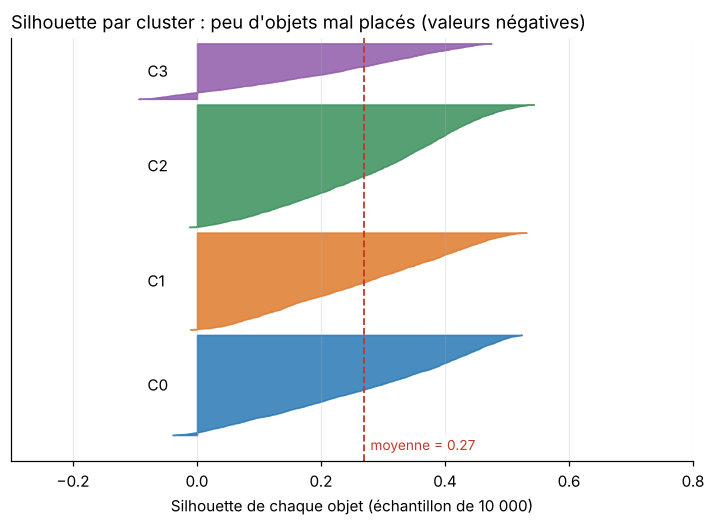

,silhouette moyenne
0,0.276
1,0.270
2,0.289
3,0.212


In [13]:
sil = silhouette_samples(X[sample], data["cluster"].to_numpy()[sample])
fig, ax = plt.subplots(figsize=(8, 5))
y0 = 0
for c in range(K):
    vals = np.sort(sil[data["cluster"].to_numpy()[sample] == c])
    ax.fill_betweenx(np.arange(y0, y0 + len(vals)), 0, vals, color=CLUSTER_COLORS[c], alpha=0.85)
    ax.text(-0.08, y0 + len(vals) / 2, f"C{c}", va="center", fontsize=10)
    y0 += len(vals) + 150
ax.axvline(sil.mean(), color=RED, ls="--", lw=1.2)
ax.text(sil.mean() + 0.01, -400, f"moyenne = {sil.mean():.2f}", color=RED, fontsize=9, bbox=LABEL_BOX)
ax.set_xlabel("Silhouette de chaque objet (échantillon de 10 000)")
ax.set_yticks([])
ax.set_ylim(-700, y0)
ax.set_xlim(-0.3, 0.8)
ax.set_title("Silhouette par cluster : peu d'objets mal placés (valeurs négatives)", loc="left")
save(fig, "silhouette_par_cluster")
plt.show()
pd.Series(sil).groupby(data["cluster"].to_numpy()[sample]).mean().rename("silhouette moyenne").to_frame()

## 8. Des clusters aux campagnes d'observation

Le tableau ci-dessous traduit chaque cluster en **stratégie de suivi**. Les noms et les recommandations sont tirés des chiffres du portrait (section 5) ; relisez-les si vous relancez le notebook sur d'autres données.

In [14]:
def describe(row):
    big = row["diametre_median_m"] >= 140
    close = row["moid_median_UA"] <= 0.02
    inclined = row["inclinaison_mediane"] >= 20
    if not big and close:
        return ("Petits objets frôleurs",
                "Détectés surtout lors de passages très proches. Suivi réactif juste après la découverte, puis surveillance passive.")
    if not big:
        return ("Petits objets à distance modérée",
                "Faible risque individuel. Surveillance passive par les relevés automatiques.")
    if inclined:
        return ("Gros objets très inclinés",
                "Gros mais loin en moyenne. Orbites peu accessibles : suivi astrométrique régulier, fenêtres d'observation spécifiques.")
    return ("Gros objets proches de l'écliptique",
            "Réservoir principal de PHA. Campagne de suivi prioritaire et récurrente.")

campaigns = profile.copy()
campaigns[["profil", "stratégie de suivi"]] = campaigns.apply(lambda r: pd.Series(describe(r)), axis=1)
campaign_table = campaigns[["profil", "objets", "diametre_median_m", "moid_median_UA", "inclinaison_mediane",
                            "part_PHA", "part_de_tous_les_PHA", "stratégie de suivi"]]
campaign_table.to_csv(REPORT_DIR / "campagnes_par_cluster.csv")
campaign_table.round(3)

,profil,objets,diametre_median_m,moid_median_UA,inclinaison_mediane,part_PHA,part_de_tous_les_PHA,stratégie de suivi
cluster,,,,,,,,
0,Petits objets frôleurs,11002,18.582,0.005,4.030,0.010,0.042,Détectés surtout lors de passages très proches...
1,Petits objets à distance modérée,10845,41.898,0.046,11.290,0.022,0.095,Faible risque individuel. Surveillance passive...
2,Gros objets proches de l'écliptique,13288,162.880,0.078,7.485,0.122,0.640,Réservoir principal de PHA. Campagne de suivi ...
3,Gros objets très inclinés,6015,383.364,0.170,28.470,0.094,0.223,Gros mais loin en moyenne. Orbites peu accessi...


In [15]:
data[["pdes", "cluster", "diametre_km", "moid_au", "i", "e", "pha", "proba_pha", "signale"]].to_csv(
    PROCESSED_DIR / "clusters_catalogue.csv", index=False)
print(f"Clusters enregistrés pour {fmt(len(data))} objets dans data/processed/06_clustering/clusters_catalogue.csv")

Clusters enregistrés pour 41 150 objets dans data/processed/06_clustering/clusters_catalogue.csv


## Synthèse

| Question | Réponse |
|---|---|
| Pourquoi ces variables ? | Une par dimension du risque (taille, proximité, inclinaison, excentricité). Les corrélations montrent que `a`, `q` et `ad` sont redondantes ; l'ACP montre qu'aucune des 4 retenues n'est superflue (3 composantes pour dépasser 90 % de l'information). |
| Combien de groupes ? | **4**, choisis par silhouette et méthode du coude. |
| Les groupes sont-ils nets ? | **Non** (silhouette ≈ 0,27) : ils se chevauchent, car les géocroiseurs forment un continuum. Ils sont en revanche **reproductibles** (ARI élevé entre relances). |
| Apportent-ils quelque chose de nouveau ? | **Oui** : ils mélangent les familles orbitales officielles et suivent des critères de risque (taille, proximité, inclinaison). |
| Que révèlent-ils ? | Les petits objets sont concentrés à faible MOID, les gros à MOID plus élevé : c'est en partie le **biais de détection** (un petit objet n'est vu que s'il passe tout près). |
| Usage pour la PDCO | Le cluster des gros objets proches de l'écliptique concentre près des deux tiers des PHA ; il justifie une campagne prioritaire. Les petits frôleurs relèvent d'un suivi réactif à la découverte, cohérent avec la recommandation de l'étape 5. |
| Pour l'étape 7 | Le cluster de chaque objet est une colonne de plus dans la file de priorité, utile pour regrouper les observations. |